<a href="https://colab.research.google.com/github/ALISSONRABELOTEIXEIRA/1TIAOB-FASE5-CAP1/blob/main/Alisson_Vinicius_de_Souza_Rabelo_Teixeira_pbl_fase6AAAA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Conecta o Google Drive para acessar os arquivos.

In [ ]:
# Importa o acesso ao Google Drive.
from google.colab import drive
# Conecta o Drive ao Colab.
drive.mount('/content/drive')


Mounted at /content/drive


##Baixa o YOLOv5 para o ambiente.

In [ ]:
# Baixa o repositório do YOLOv5.
! git clone https://github.com/ultralytics/yolov5.git


Cloning into 'yolov5'...
remote: Enumerating objects: 18770, done.
remote: Counting objects: 100% (327/327), done.
remote: Compressing objects: 100% (199/199), done.
remote: Total 18770 (delta 264), reused 128 (delta 128), pack-reused 18443 (from 5)
Receiving objects: 100% (18770/18770), 17.83 MiB | 68.12 MiB/s, done.
Resolving deltas: 100% (12769/12769), done.


##Instala as dependências do YOLOv5.

In [ ]:
# Instala as dependências do YOLOv5.
! pip install -r yolov5/requirements.txt


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 35.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.8/96.8 kB 13.2 MB/s eta 0:00:00


#Copia a configuração dos dados para o YOLOv5.

In [ ]:
# Copia a configuração do conjunto de dados.
! cp /content/drive/MyDrive/Imagens_Cap1/Dataset/config.yaml yolov5/data/


#Treina e valida o modelo por 30 épocas.

In [ ]:
# Treina o YOLOv5s por 30 épocas, com imagens de 640 pixels.
!python yolov5/train.py --data drive/MyDrive/Imagens_Cap1/Dataset/config.yaml --weights yolov5s.pt --img 640 --epochs 30


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
I0000 00:00:1791922308.057467    1281 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791922309.129096    1281 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_

#Detecta objetos nas imagens de teste com o modelo mais recente.

In [ ]:
# Importa funções para acessar pastas e arquivos.
import os
# Permite executar comandos externos.
import subprocess

# Define a função que localiza o treinamento mais recente.
def get_latest_train_run_folder():
    # Lista as pastas de treinamento.
    subfolders = [f.path for f in os.scandir('yolov5/runs/train') if f.is_dir()]
    # Seleciona a pasta com o maior valor de ctime.
    latest_folder = max(subfolders, key=os.path.getctime, default=None)
    # Retorna a pasta encontrada ou None.
    return latest_folder

# Busca o treinamento mais recente.
latest_run = get_latest_train_run_folder()

# Continua se houver uma pasta de treinamento.
if latest_run:
    # Mostra a pasta do modelo selecionado.
    print("Modelo utilizado:", latest_run)

    # Executa a detecção com os parâmetros abaixo.
    result = subprocess.run(
        # Chama o script de detecção.
        f'python yolov5/detect.py '
        # Carrega os melhores pesos do treinamento.
        f'--weights {latest_run}/weights/best.pt '
        # Define o tamanho de entrada como 640 pixels.
        f'--img 640 '
        # Aceita detecções com confiança mínima de 10%.
        f'--conf-thres 0.10 '
        # Usa as imagens da pasta de teste.
        f'--source drive/MyDrive/Imagens_Cap1/Dataset/test/ '
        # Informa a configuração do conjunto de dados.
        f'--data yolov5/data/config.yaml',
        # Executa o comando pelo shell.
        shell=True,
        # Captura as saídas do comando.
        capture_output=True,
        # Retorna as saídas como texto.
        text=True
    )

    # Exibe a saída padrão.
    print(result.stdout)
    # Exibe mensagens enviadas à saída de erro.
    print(result.stderr)

# Trata a ausência de uma pasta de treinamento.
else:
    # Informa que nenhum treinamento foi encontrado.
    print("Não foi possível encontrar a pasta de treinamento mais recente.")


Modelo utilizado: yolov5/runs/train/exp
detect: weights=['yolov5/runs/train/exp/weights/best.pt'], source=drive/MyDrive/Imagens_Cap1/Dataset/test/, data=yolov5/data/config.yaml, imgsz=[640, 640], conf_thres=0.1, iou_thres=0.45, max_det=1000, device=, view_img=False, save_txt=False, save_format=0, save_csv=False, save_conf=False, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, update=False, project=yolov5/runs/detect, name=exp, exist_ok=False, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
image 1/10 /content/drive/MyDrive/Imagens_Cap1/Dataset/test/panda1.JPG: 448x640 1 Panda, 12.4ms
image 2/10 /content/drive/MyDrive/Imagens_Cap1/Dataset/test/panda2.jpg: 576x640 1 Porco, 16.5ms
image 3/10 /content/d

#Treina e valida um novo modelo por 60 épocas.

In [ ]:
# Treina o YOLOv5s por 60 épocas, com imagens de 640 pixels.
!python yolov5/train.py --data drive/MyDrive/Imagens_Cap1/Dataset/config.yaml --weights yolov5s.pt --img 640 --epochs 60


WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
I0000 00:00:1791922401.233554    2049 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791922402.303151    2049 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791922402.303416    2049 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice: (30 second timeout

#Repete a detecção nas imagens de teste com o modelo mais recente.

In [ ]:
# Importa funções para acessar pastas e arquivos.
import os
# Permite executar comandos externos.
import subprocess

# Define a função que localiza o treinamento mais recente.
def get_latest_train_run_folder():
    # Lista as pastas de treinamento.
    subfolders = [f.path for f in os.scandir('yolov5/runs/train') if f.is_dir()]
    # Seleciona a pasta com o maior valor de ctime.
    latest_folder = max(subfolders, key=os.path.getctime, default=None)
    # Retorna a pasta encontrada ou None.
    return latest_folder

# Busca o treinamento mais recente.
latest_run = get_latest_train_run_folder()

# Continua se houver uma pasta de treinamento.
if latest_run:
    # Mostra a pasta do modelo selecionado.
    print("Modelo utilizado:", latest_run)

    # Executa a detecção com os parâmetros abaixo.
    result = subprocess.run(
        # Chama o script de detecção.
        f'python yolov5/detect.py '
        # Carrega os melhores pesos do treinamento.
        f'--weights {latest_run}/weights/best.pt '
        # Define o tamanho de entrada como 640 pixels.
        f'--img 640 '
        # Aceita detecções com confiança mínima de 10%.
        f'--conf-thres 0.10 '
        # Usa as imagens da pasta de teste.
        f'--source drive/MyDrive/Imagens_Cap1/Dataset/test/ '
        # Informa a configuração do conjunto de dados.
        f'--data yolov5/data/config.yaml',
        # Executa o comando pelo shell.
        shell=True,
        # Captura as saídas do comando.
        capture_output=True,
        # Retorna as saídas como texto.
        text=True
    )

    # Exibe a saída padrão.
    print(result.stdout)
    # Exibe mensagens enviadas à saída de erro.
    print(result.stderr)

# Trata a ausência de uma pasta de treinamento.
else:
    # Informa que nenhum treinamento foi encontrado.
    print("Não foi possível encontrar a pasta de treinamento mais recente.")


Modelo utilizado: yolov5/runs/train/exp2
detect: weights=['yolov5/runs/train/exp2/weights/best.pt'], source=drive/MyDrive/Imagens_Cap1/Dataset/test/, data=yolov5/data/config.yaml, imgsz=[640, 640], conf_thres=0.1, iou_thres=0.45, max_det=1000, device=, view_img=False, save_txt=False, save_format=0, save_csv=False, save_conf=False, save_crop=False, nosave=False, classes=None, agnostic_nms=False, augment=False, update=False, project=yolov5/runs/detect, name=exp, exist_ok=False, line_thickness=3, hide_labels=False, hide_conf=False, half=False, dnn=False, vid_stride=1
YOLOv5 🚀 v7.0-556-gf9578796 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)

Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients, 15.8 GFLOPs
image 1/10 /content/drive/MyDrive/Imagens_Cap1/Dataset/test/panda1.JPG: 448x640 1 Panda, 11.6ms
image 2/10 /content/drive/MyDrive/Imagens_Cap1/Dataset/test/panda2.jpg: 576x640 1 Panda, 12.6ms
image 3/10 /content

#Exibe as imagens com as detecções do modelo.

Imagem: panda1.JPG


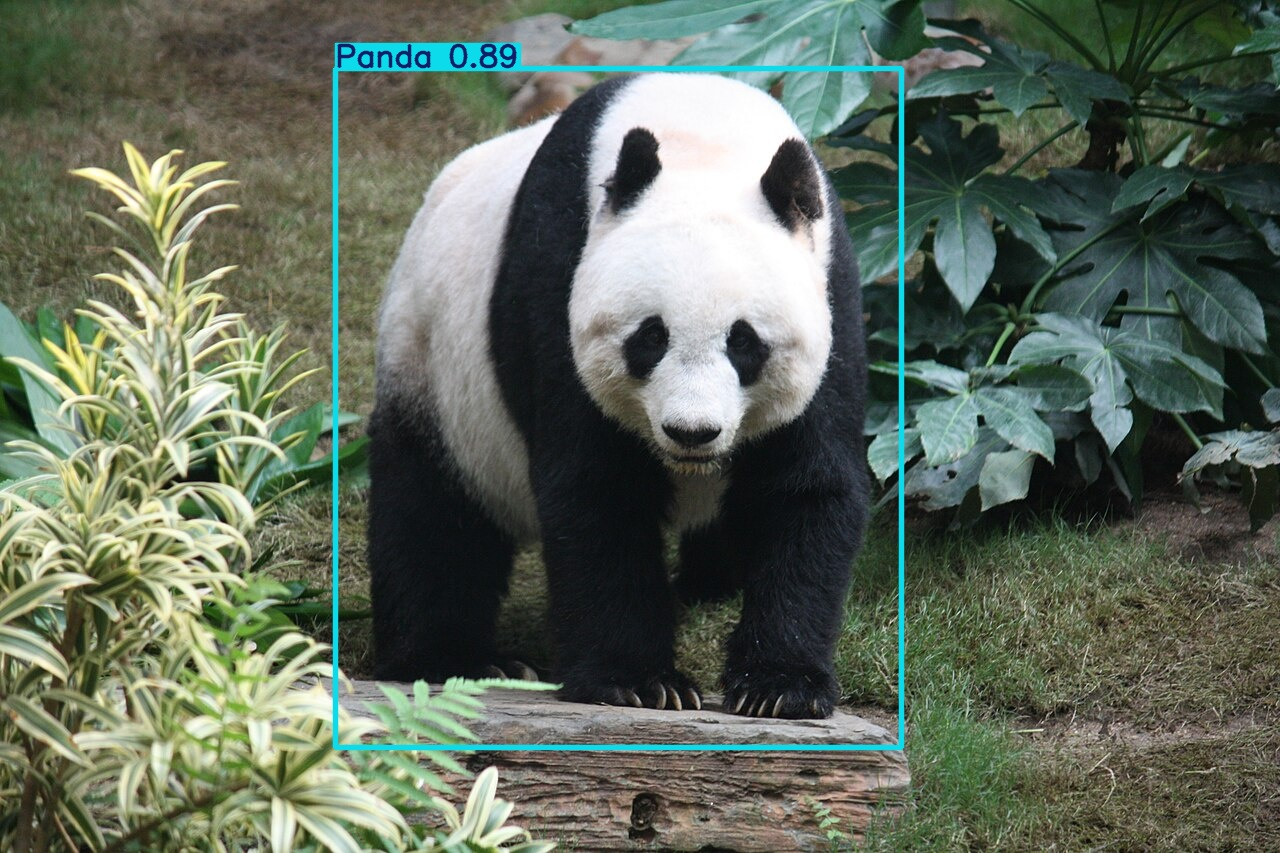

Imagem: panda2.jpg


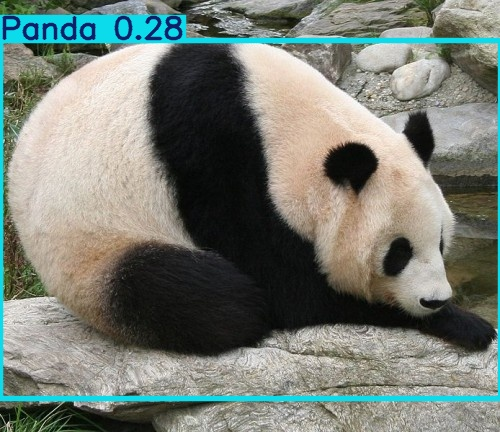

Imagem: panda3.jpg


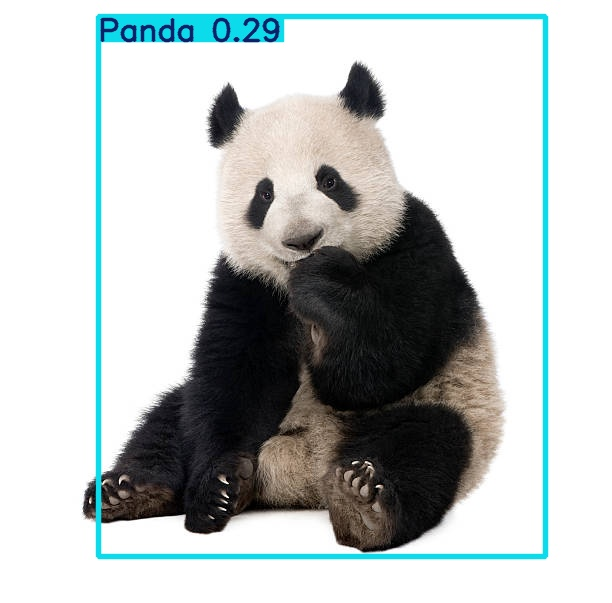

Imagem: panda4.jpg


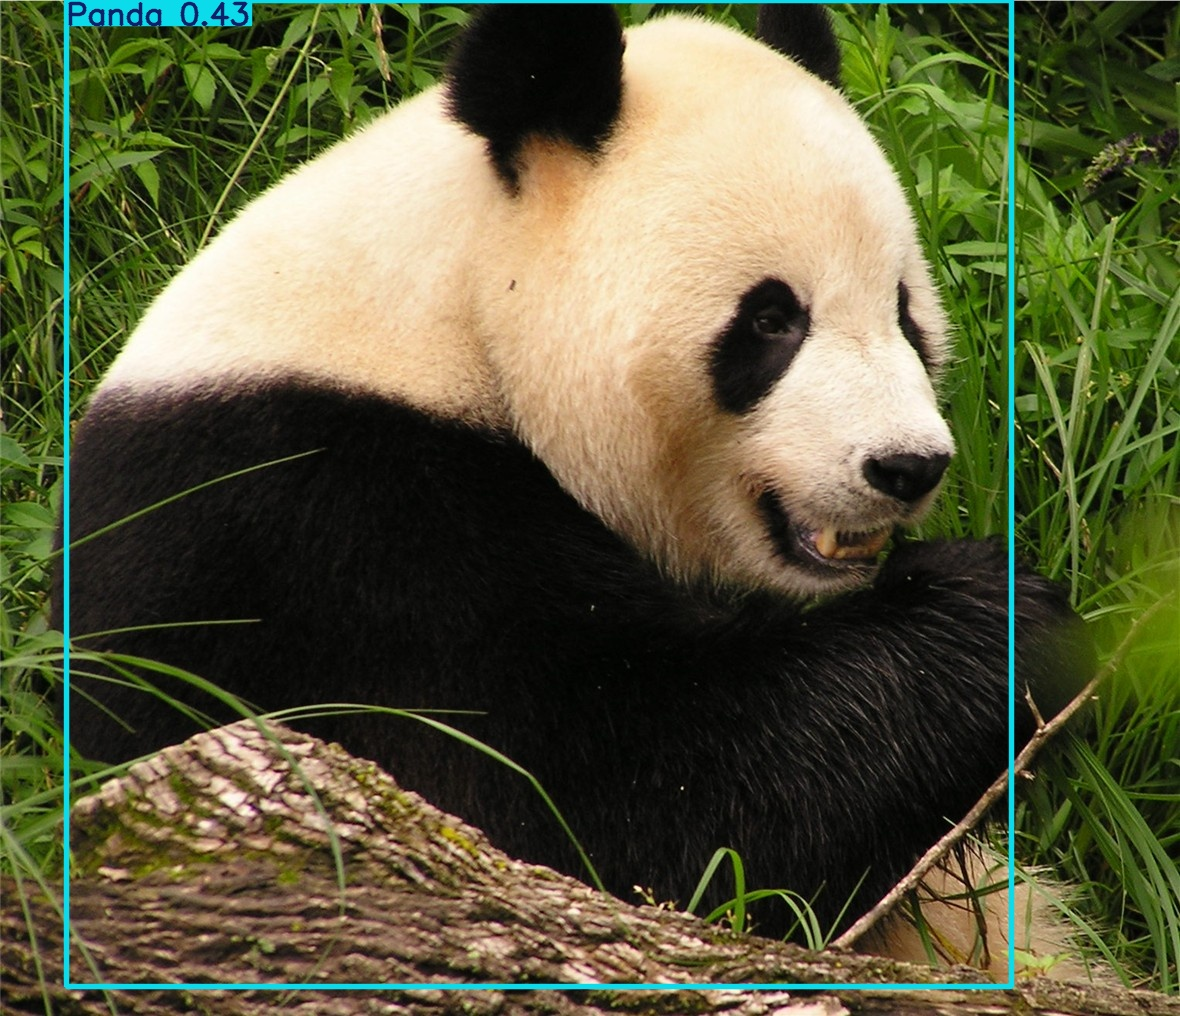

Imagem: panda5.jpg


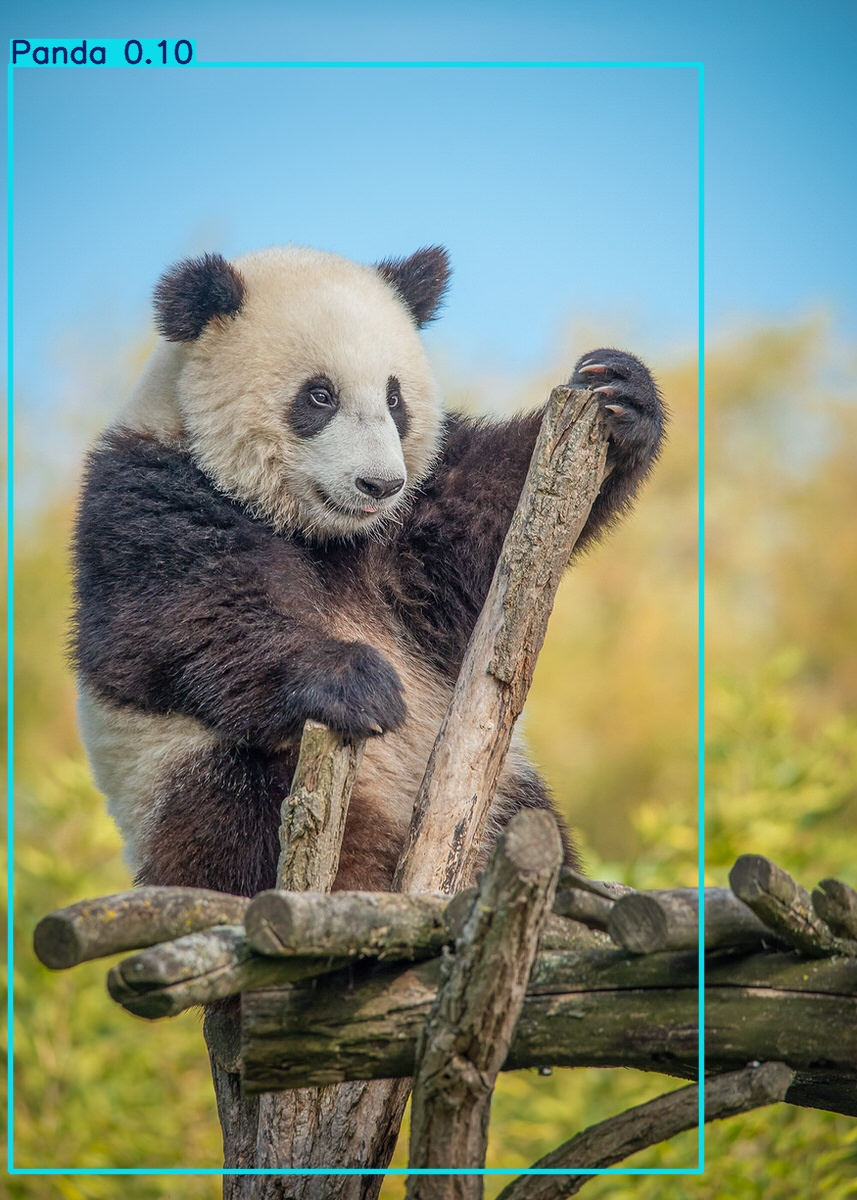

Imagem: porco1.jpg


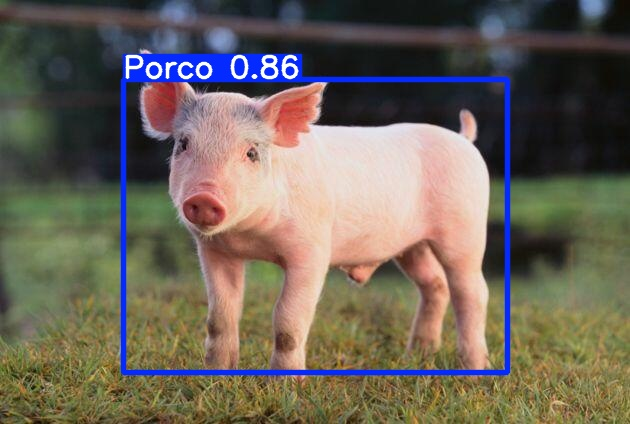

Imagem: porco2.jpg


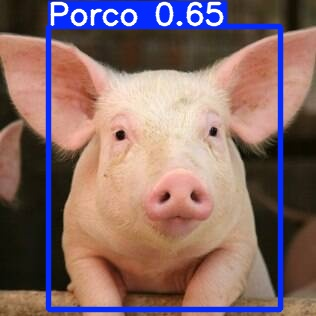

Imagem: porco3.jpg


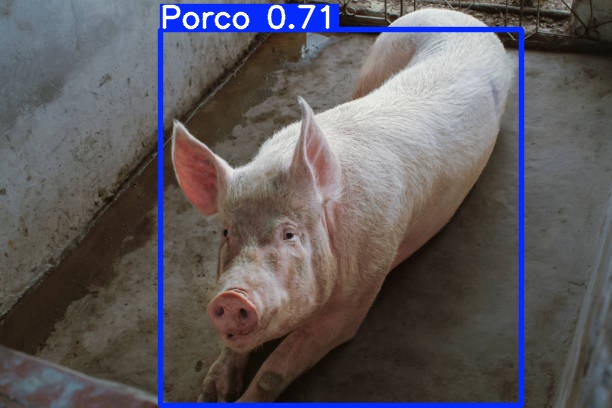

Imagem: porco4.jpg


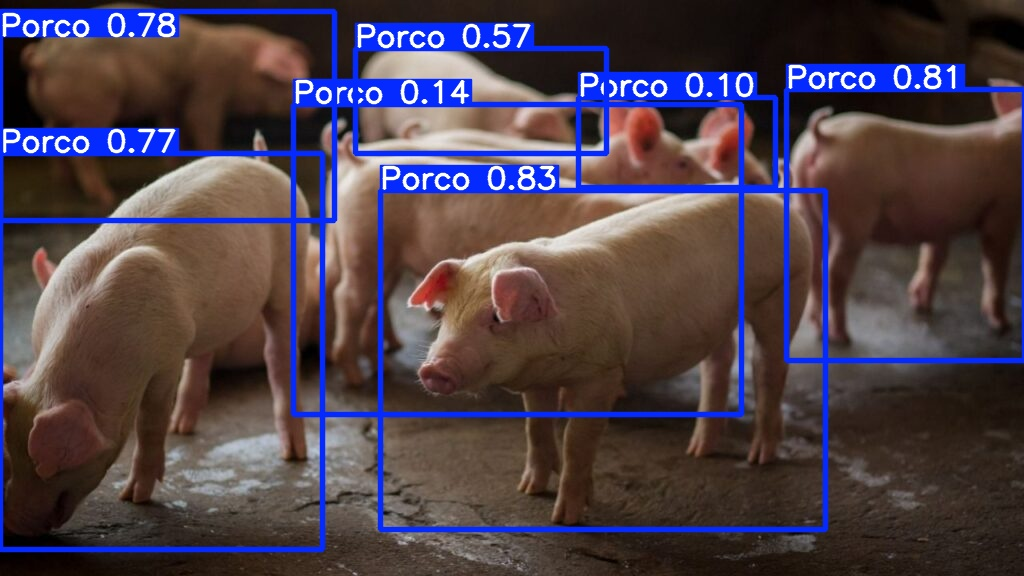

Imagem: porco5.jpg


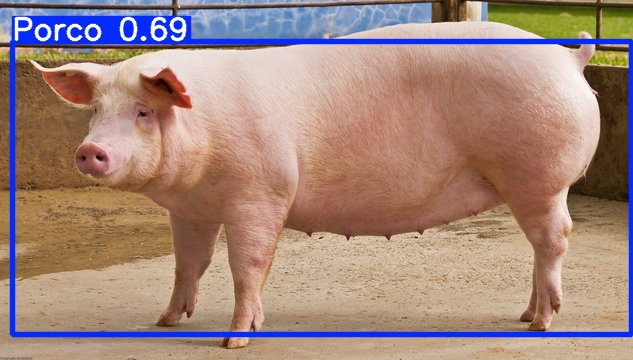

In [ ]:
from IPython.display import Image, display
from pathlib import Path

# Pasta onde estão as imagens detectadas
pasta = Path('/content/yolov5/runs/detect/exp2')

# Listar os arquivos de imagem da pasta
imagens = sorted(
    arquivo for arquivo in pasta.glob('*')
    if arquivo.suffix.lower() in {'.jpg', '.jpeg', '.png'}
)

# Exibir todas as imagens
for imagem in imagens:
    print(f"Imagem: {imagem.name}")
    display(Image(filename=str(imagem)))

#Passo a passo: Treinamento, Validação e treino

## 1. Treinamento
- Acessar os dados no Google Drive e instalar o YOLOv5.
- Carregar o `config.yaml`, que indica os dados e as classes.
- Treinar o YOLOv5s com imagens de 640 pixels em dois experimentos: 30 e 60 épocas.
- Ajustar os pesos para aprender a detectar porcos e pandas.

## 2. Validação
- Avaliar o modelo nos dados de validação durante o treinamento, sem atualizar os pesos.
- Acompanhar precisão, recall e mAP para verificar a qualidade das detecções.
- Comparar os experimentos: o de 60 épocas apresentou melhores métricas de validação.
- Salvar o melhor modelo de cada treinamento em `best.pt`.

## 3. Teste
- Carregar o `best.pt` do treinamento mais recente.
- Executar a detecção nas 10 imagens da pasta de teste, com confiança mínima de 10%.
- Exibir as imagens e observar classes e caixas detectadas.
- Nesta etapa, o notebook permite avaliação visual; não calcula precisão, recall ou mAP de teste.


##Conclusão das épocas e resultados



Resultados gerais de **validação** do melhor modelo de cada treinamento:

| Métrica | 30 épocas | 60 épocas | Aumento |
|---|---:|---:|---:|
| Precisão | 63,9% | 84,3% | 20,4 pontos percentuais |
| Recall | 48,2% | 62,4% | 14,2 pontos percentuais |
| mAP50 | 58,9% | 77,3% | 18,4 pontos percentuais |
| mAP50-95 | 25,9% | 37,6% | 11,7 pontos percentuais |

- **Precisão:** com 60 épocas, uma proporção maior das detecções estava correta.
- **Recall:** o modelo conseguiu identificar uma proporção maior dos objetos existentes.
- **mAP50:** houve melhora na qualidade geral das detecções.
- **mAP50-95:** houve melhora também sob critérios mais rigorosos de localização das caixas.

**Conclusão:** o treinamento de 60 épocas apresentou melhores resultados nas quatro métricas de validação, embora ainda haja espaço para melhorar a identificação e a localização dos objetos.

# Relatório de resultados e conclusões

### Achados
Nos gráficos fornecidos nas pastas de 30 e 60 épocas, o **mAP50 aumentou de 55,4% para 84,6%**. A melhora foi maior para pandas: o AP50 passou de 52,2% para 99,5%; para porcos, de 58,6% para 69,7%. Esses valores vêm das curvas de precisão e recall dessas pastas e diferem dos registros anteriores do notebook.

### Pontos fortes e limitações
As curvas mostram redução das perdas de treinamento e melhora na localização e classificação durante a validação. As matrizes de confusão indicam menos objetos não detectados, principalmente pandas. Ainda persistem falhas na detecção de porcos, falsos positivos e limitações na localização precisa das caixas. A perda de presença de objetos na validação oscila e aumenta em parte do treino de 60 épocas, exigindo atenção à generalização.

### Conclusão
O treinamento de **60 épocas apresentou melhor desempenho**, mas isso não garante o mesmo resultado em novas imagens. A validação pequena e o teste apenas visual limitam o trabalho. Ampliar os dados e calcular métricas em um teste independente e anotado são os próximos passos.
